# 02 - Airline reviews: preprocessing, features, models, evaluation

A guided walk through the pipeline in `airline_reviews` (the full version is
`uv run airline-reviews run`, whose committed results are in `results/`). Everything below is computed
live from `data/full_airline_review.csv`; the model-comparison table at the end is read from the committed
full run.

Questions: (1) can the text of a review predict whether the reviewer *recommends* the airline? (2) can it
predict the 1-10 overall rating? (3) what is wrong with the original preprocessing recipe?

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, Markdown, display
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

from airline_reviews.config import DEFAULT_RESULTS_DIR
from airline_reviews.data import load_reviews, train_test_split_reviews
from airline_reviews.evaluate import classification_metrics
from airline_reviews.features import make_tfidf
from airline_reviews.pipeline import preprocess_frame
from airline_reviews.text import TextPreprocessor

sns.set_theme(style='whitegrid')
pd.set_option('display.width', 140)
pd.set_option('display.max_colwidth', 90)

## 1. Data

`load_reviews` drops exact duplicates (so a review cannot sit in both the train and test split), and adds a 0/1 `label` from `recommended`.

In [2]:
df = load_reviews()
print(f'{len(df):,} reviews, {df.airline.nunique()} airlines, {df.label.mean():.1%} recommended')
df[['rating', 'recommended', 'airline', 'header']].head()

15,252 reviews, 10 airlines, 53.8% recommended


,rating,recommended,airline,header
0,3,no,singapore-airlines,food were served last
1,5,no,singapore-airlines,"seat spacing is less"""
2,10,yes,singapore-airlines,service was efficient and friendly
3,1,no,singapore-airlines,“Very disappointed”
4,1,no,singapore-airlines,incompetent customer service


## 2. Preprocessing: what the original recipe throws away

The coursework recipe keeps only tokens that appear in the NLTK `words` dictionary, drops stop words, then lemmatises. Let's measure what survives.

In [3]:
import nltk

prep = TextPreprocessor()
sample = df.sample(500, random_state=0)
alpha_tokens = kept_tokens = 0
for text in sample.content:
    toks = [t.lower() for t in nltk.word_tokenize(text) if t.isalpha()]
    alpha_tokens += len(toks)
    kept_tokens += len(prep(text).split())
print(f'alphabetic tokens kept by the recipe: {kept_tokens / alpha_tokens:.1%}')

examples = ['The seats were not comfortable and the flights were delayed.',
            'Passengers were running late, children cried, no food was served.']
for text in examples:
    print(f'{text!r}\n  -> {prep(text)!r}')

alphabetic tokens kept by the recipe: 39.4%
'The seats were not comfortable and the flights were delayed.'
  -> 'comfortable'
'Passengers were running late, children cried, no food was served.'
  -> 'run late cry food'


Inflected words ("seats", "flights", "delayed", "passengers", "children") are missing from the
dictionary, and negations ("not", "no") are stop words. The cleaned text therefore loses much of the
sentiment signal; the comparison below quantifies the cost.

In [4]:
df = preprocess_frame(df)      # adds clean_* text columns and VADER scores (cached in data/processed)
rho = spearmanr(df.compound, df.rating).statistic
print(f'Spearman(VADER compound, rating) = {rho:.3f}')
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.boxplot(data=df, x='rating', y='compound', color='#a8dadc', fliersize=1, ax=ax)
ax.set_title('VADER compound score by rating'); plt.show()

Spearman(VADER compound, rating) = 0.722


## 3. Train / test split and models

The split is stratified and fixed (seed 42). Vectorisers are fitted on the training part only.

In [5]:
train, test = train_test_split_reviews(df)
print(len(train), len(test), f'(test positive rate {test.label.mean():.3f})')

def evaluate(text_col, C=2.0):
    model = make_pipeline(make_tfidf(), LogisticRegression(C=C, max_iter=2000))
    model.fit(train[text_col], train.label)
    pred = model.predict(test[text_col])
    return model, pred, classification_metrics(test.label, pred, model.predict_proba(test[text_col])[:, 1])

model_raw, pred_raw, m_raw = evaluate('text')
_, _, m_clean = evaluate('clean_text')
pd.DataFrame({'raw text': m_raw, 'original cleaning': m_clean}).T[['accuracy', 'precision', 'recall', 'f1', 'roc_auc']].round(3)

12201 3051 (test positive rate 0.538)


,accuracy,precision,recall,f1,roc_auc
raw text,0.853491,0.860859,0.867683,0.864258,0.905702
original cleaning,0.838086,0.846433,0.853659,0.85003,0.899014


Same model, same split; only the input text differs. The original cleaning costs accuracy.

In [6]:
vec, clf = model_raw[0], model_raw[-1]
names = np.array(vec.get_feature_names_out())
order = np.argsort(clf.coef_[0])
print('towards "not recommended":', ', '.join(names[order[:12]]))
print('towards "recommended":    ', ', '.join(names[order[::-1][:12]]))

towards "not recommended": no, worst, not, poor, ba, rude, the worst, terrible, never, horrible, they, told
towards "recommended":     excellent, always, great, on time, good, comfortable, thank, amazing, friendly, the best, best, professional


Note the abbreviation **ba** (British Airways) among the negative terms: part of what the bag-of-words
model learns is airline identity, because airlines differ a lot in how often they are recommended.
The per-airline breakdown below shows how accuracy varies.

In [7]:
test = test.assign(pred=pred_raw, correct=pred_raw == test.label)
test.groupby('airline').agg(n=('correct', 'size'), accuracy=('correct', 'mean'),
                            recommended=('label', 'mean')).round(3).sort_values('n', ascending=False)

,n,accuracy,recommended
airline,,,
british-airways,713,0.857,0.403
emirates,468,0.868,0.470
qatar-airways,465,0.822,0.778
southwest-airlines,356,0.851,0.368
singapore-airlines,287,0.882,0.697
air-france,270,0.859,0.448
airasia,176,0.886,0.466
korean-air,133,0.820,0.707
asiana-airlines,102,0.863,0.804


## 4. Error analysis: confident mistakes

Reviews the model is most sure about and gets wrong.

In [8]:
proba = model_raw.predict_proba(test.text)[:, 1]
wrong = test.assign(p_recommended=proba)[~test.correct]
wrong = wrong.assign(confidence=np.abs(wrong.p_recommended - 0.5)).sort_values('confidence', ascending=False)
for _, r in wrong.head(4).iterrows():
    print(f"rating {r.rating:2d}, recommended={r.recommended!r:5}, model P(rec)={r.p_recommended:.2f}")
    print('   ', (r.header + ' - ' + r.content)[:230].replace('\n', ' '), '...')

rating  9, recommended='no' , model P(rec)=0.99
    Emirates customer review - My flights were EK16 LGW-DXB 26 May 2014 connecting EK384 DXB-BKK 27 May 2014. Ground staff both at Gatwick and Dubai were polite and friendly. Very quick and smooth checking in and boarding. Both flight ...
rating 10, recommended='no' , model P(rec)=0.98
    Korean Air customer review - Two recent flights in economy were excellent. Kansai to Seoul and Seoul to Sydney. Flights were on time service was friendly and efficient. Both A330s were new and spotless with plenty of leg room in e ...
rating  9, recommended='no' , model P(rec)=0.98
    Absolutely fabulous experience - Adelaide to London via Doha in business class. Absolutely fabulous experience, flew their A350 to Doha and A380 onwards to London. Ground service was efficient, and transfer in Doha was pleasant. A ...
rating 10, recommended='no' , model P(rec)=0.98
    Qatar Airways customer review - MAD-DEL via Doha return on 777-300 and 787 both ways. A

The most confident mistakes shown here are reviews whose text is clearly positive and whose rating is 9-10,
but whose author ticked "not recommended": label noise rather than model failure. The table below
shows how often rating and verdict disagree (about 5% of 1-star reviews say "recommended", about 6% of 10-star
reviews say "not recommended"), so text-only models cannot reach 100%. Where exactly the ceiling lies is not measured here.

In [9]:
print('rating vs recommended on the whole dataset (share recommended):')
(df.groupby('rating').label.mean().round(2).to_frame('share recommended').T)

rating vs recommended on the whole dataset (share recommended):


rating,1,2,3,4,5,6,7,8,9,10
share recommended,0.05,0.1,0.14,0.21,0.4,0.69,0.85,0.91,0.92,0.94


## 5. Full-run results (committed `results/metrics.json`)

Produced by `uv run airline-reviews run --glove <glove.840B.300d.zip> --transformer`; includes the two-channel LSTM and the zero-shot transformer baseline.

In [10]:
metrics = json.loads((DEFAULT_RESULTS_DIR / 'metrics.json').read_text())
meta = metrics['meta']
print(f"{meta['n_train']:,} train / {meta['n_test']:,} test reviews; seed {meta['seed']}")
clf = pd.DataFrame(metrics['classification'])
clf['f1 95% CI'] = clf.f1_ci.map(lambda ci: f'{ci[0]:.3f}-{ci[1]:.3f}')
clf[['name', 'accuracy', 'precision', 'recall', 'f1', 'f1 95% CI', 'roc_auc']].sort_values('f1', ascending=False).round(3).reset_index(drop=True)

12,201 train / 3,051 test reviews; seed 42


,name,accuracy,precision,recall,f1,f1 95% CI,roc_auc
0,tfidf + LR (raw),0.853,0.861,0.868,0.864,0.851-0.877,0.906
1,tfidf + SVM (raw),0.853,0.857,0.871,0.864,0.851-0.876,0.906
2,tfidf + LR (clean),0.838,0.846,0.854,0.850,0.837-0.863,0.899
3,two-channel LSTM + GloVe,0.833,0.842,0.849,0.845,0.831-0.858,0.908
4,tfidf + NB (raw),0.828,0.832,0.852,0.842,0.829-0.855,0.881
5,two-channel LSTM (random init),0.810,0.824,0.821,0.822,0.807-0.837,0.881
6,vader + LR,0.806,0.815,0.827,0.821,0.806-0.834,0.867
7,DistilBERT SST-2 (zero-shot),0.790,0.904,0.681,0.777,0.759-0.794,0.892
8,majority,0.538,0.538,1.000,0.699,0.684-0.714,0.500


In [11]:
reg = pd.DataFrame(metrics['regression'])
reg[['name', 'mae', 'rmse', 'r2', 'spearman', 'within_1']].round(3)

,name,mae,rmse,r2,spearman,within_1
0,mean rating,3.147,3.435,-0.000,NaN,0.177
1,vader + Ridge,1.690,2.160,0.604,0.764,0.530
2,tfidf + Ridge (raw),1.334,1.712,0.752,0.847,0.632


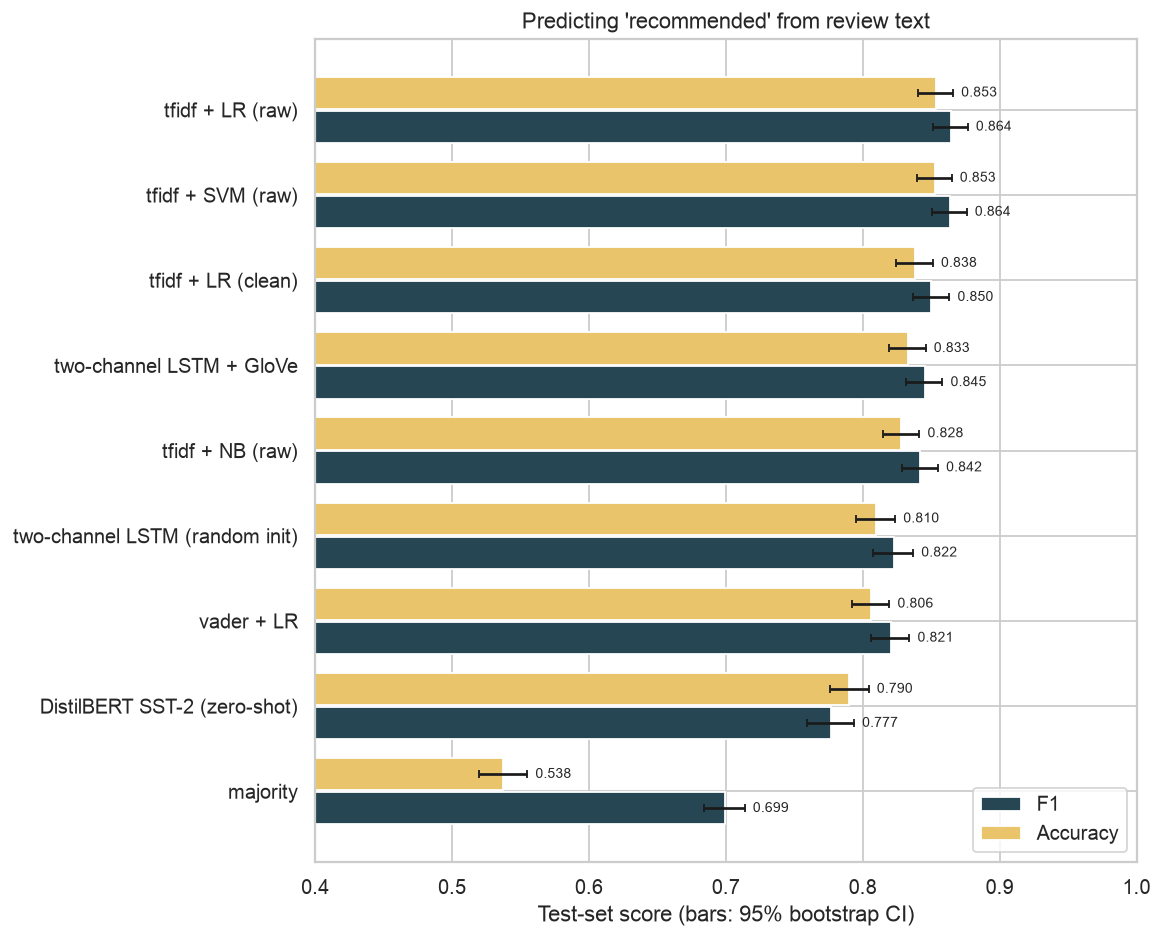

In [12]:
display(Image(filename=str(DEFAULT_RESULTS_DIR / 'figures' / 'model_comparison.png')))